In [9]:
!pip install -q open_clip_torch kagglehub

In [15]:
import kagglehub, os
kagglehub.login()    # paste your Kaggle username and API key if asked
path = kagglehub.dataset_download("xhlulu/140k-real-and-fake-faces")
base = os.path.join(path, "real_vs_fake", "real-vs-fake")
print(base, os.listdir(base))   # expect: train, valid, test

Using Colab cache for faster access to the '140k-real-and-fake-faces' dataset.
/kaggle/input/140k-real-and-fake-faces/real_vs_fake/real-vs-fake ['valid', 'test', 'train']
Kaggle credentials set.
Kaggle credentials successfully validated.


In [16]:
import torch, open_clip
from PIL import Image
import numpy as np

device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)
model, _, preprocess = open_clip.create_model_and_transforms("ViT-B-32", pretrained="openai")
model = model.to(device).eval()

device: cuda


In [17]:
import glob
from tqdm import tqdm

def list_images(folder):
    exts = (".jpg", ".jpeg", ".png", ".webp")
    return sorted(p for p in glob.glob(os.path.join(folder, "**", "*"), recursive=True)
                  if p.lower().endswith(exts))

@torch.no_grad()
def embed_batch(paths, batch_size=64):
    chunks = []
    for i in tqdm(range(0, len(paths), batch_size)):
        batch = [preprocess(Image.open(p).convert("RGB")) for p in paths[i:i+batch_size]]
        x = torch.stack(batch).to(device)
        v = model.encode_image(x)
        v = v / v.norm(dim=-1, keepdim=True)
        chunks.append(v.cpu().numpy())
    return np.concatenate(chunks)

In [18]:
import random
random.seed(42)

def sample_split(split, n_per_class):
    real = random.sample(list_images(f"{base}/{split}/real"), n_per_class)
    fake = random.sample(list_images(f"{base}/{split}/fake"), n_per_class)
    X = embed_batch(real + fake)
    y = np.array([0]*len(real) + [1]*len(fake))   # real=0, fake=1
    return X, y

Xtr, ytr = sample_split("train", 500)
Xva, yva = sample_split("valid", 200)

from google.colab import drive
drive.mount("/content/drive")
np.savez("/content/drive/MyDrive/embeddings_small.npz", Xtr=Xtr, ytr=ytr, Xva=Xva, yva=yva)

100%|██████████| 7/7 [00:04<00:00,  1.69it/s]


Mounted at /content/drive


In [19]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, roc_auc_score

clf = LogisticRegression(max_iter=1000, C=1.0)
clf.fit(Xtr, ytr)
p = clf.predict_proba(Xva)[:, 1]
print("val accuracy @0.5:", accuracy_score(yva, p >= 0.5))
print("val AUC:", roc_auc_score(yva, p))

val accuracy @0.5: 0.8375
val AUC: 0.9164250000000002


In [20]:
random.seed(7)
Xtr_big, ytr_big = sample_split("train", 5000)    # 10,000 images, about 2 min
Xva_big, yva_big = sample_split("valid", 1000)    # 2,000 images, tighter estimate

np.savez("/content/drive/MyDrive/embeddings_big.npz",
         Xtr=Xtr_big, ytr=ytr_big, Xva=Xva_big, yva=yva_big)

# Learning curve: train on growing slices (samples are already shuffled by class order, so shuffle first)
idx = np.random.RandomState(0).permutation(len(ytr_big))
for n in [200, 500, 1000, 2500, 5000, 10000]:
    sel = idx[:n]
    c = LogisticRegression(max_iter=2000).fit(Xtr_big[sel], ytr_big[sel])
    p = c.predict_proba(Xva_big)[:, 1]
    print(n, "acc:", round(accuracy_score(yva_big, p >= 0.5), 4),
          "auc:", round(roc_auc_score(yva_big, p), 4))

100%|██████████| 32/32 [00:21<00:00,  1.51it/s]


200 acc: 0.753 auc: 0.8362
500 acc: 0.793 auc: 0.877
1000 acc: 0.816 auc: 0.9007
2500 acc: 0.852 auc: 0.9324
5000 acc: 0.869 auc: 0.9494
10000 acc: 0.8905 auc: 0.9604


In [21]:
for C in [0.1, 1, 10, 100, 1000]:
    c = LogisticRegression(max_iter=5000, C=C).fit(Xtr_big, ytr_big)
    p = c.predict_proba(Xva_big)[:, 1]
    print(f"C={C:<6} acc: {accuracy_score(yva_big, p >= 0.5):.4f}  auc: {roc_auc_score(yva_big, p):.4f}")

C=0.1    acc: 0.8310  auc: 0.9170
C=1      acc: 0.8905  auc: 0.9604
C=10     acc: 0.9265  auc: 0.9781
C=100    acc: 0.9325  auc: 0.9808
C=1000   acc: 0.9285  auc: 0.9803


In [22]:
def embed_split(split):
    for label_name in ["real", "fake"]:
        out = f"/content/drive/MyDrive/emb_{split}_{label_name}.npz"
        if os.path.exists(out):                     # skip what's already done
            continue
        paths = list_images(f"{base}/{split}/{label_name}")
        X = embed_batch(paths)
        np.savez(out, X=X)

embed_split("valid")      # smaller, so do it first
embed_split("train")

def load_split(split):
    r = np.load(f"/content/drive/MyDrive/emb_{split}_real.npz")["X"]
    f = np.load(f"/content/drive/MyDrive/emb_{split}_fake.npz")["X"]
    return np.concatenate([r, f]), np.array([0]*len(r) + [1]*len(f))

Xtr_full, ytr_full = load_split("train")
Xva_full, yva_full = load_split("valid")
print(Xtr_full.shape, Xva_full.shape)

100%|██████████| 782/782 [08:37<00:00,  1.51it/s]


(100000, 512) (20000, 512)


In [23]:
best_C = 100   # replace with the winner from Step 3a
clf = LogisticRegression(max_iter=5000, C=best_C).fit(Xtr_full, ytr_full)
p = clf.predict_proba(Xva_full)[:, 1]
print("acc:", accuracy_score(yva_full, p >= 0.5), "auc:", roc_auc_score(yva_full, p))

acc: 0.9358 auc: 0.98443288


In [24]:
import joblib
clf = LogisticRegression(max_iter=5000, C=100).fit(Xtr_full, ytr_full)
joblib.dump(clf, "/content/drive/MyDrive/deep_clf.joblib")

['/content/drive/MyDrive/deep_clf.joblib']

In [25]:
import cv2
from PIL import Image

_face_cascade = cv2.CascadeClassifier(
    cv2.data.haarcascades + "haarcascade_frontalface_default.xml")

def _largest_face(frame_bgr):
    gray = cv2.cvtColor(frame_bgr, cv2.COLOR_BGR2GRAY)   # detector works on grayscale
    faces = _face_cascade.detectMultiScale(
        gray, scaleFactor=1.1, minNeighbors=5, minSize=(60, 60))
    if len(faces) == 0:
        return None
    return max(faces, key=lambda f: f[2] * f[3])         # biggest by area: (x, y, w, h)

def sample_frames(path, every_sec=1.0, max_frames=30, margin=0.3):
    cap = cv2.VideoCapture(path)
    if not cap.isOpened():
        raise ValueError("unreadable video")             # Backend maps this to 400
    fps = cap.get(cv2.CAP_PROP_FPS) or 25.0              # some files report 0
    step = max(1, int(round(fps * every_sec)))           # keep every step-th frame
    results, idx = [], 0
    while len(results) < max_frames:
        ok, frame = cap.read()
        if not ok:
            break
        if idx % step == 0:
            box = _largest_face(frame)
            if box is not None:
                x, y, w, h = box
                m = int(margin * max(w, h))
                H, W = frame.shape[:2]
                crop = frame[max(0, y - m):min(H, y + h + m),
                             max(0, x - m):min(W, x + w + m)]
                img = Image.fromarray(cv2.cvtColor(crop, cv2.COLOR_BGR2RGB))
                results.append((idx / fps, img))         # t in seconds
        idx += 1
    cap.release()
    return results                                       # [] means no face: Backend returns 422

Saving WhatsApp Video 2026-10-19 at 3.20.14 AM.mp4 to WhatsApp Video 2026-10-19 at 3.20.14 AM (1).mp4
11 crops; times: [1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0, 9.0, 10.0]


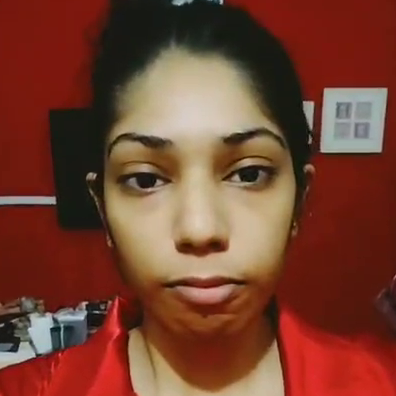

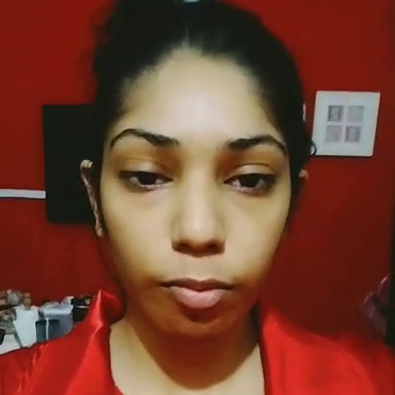

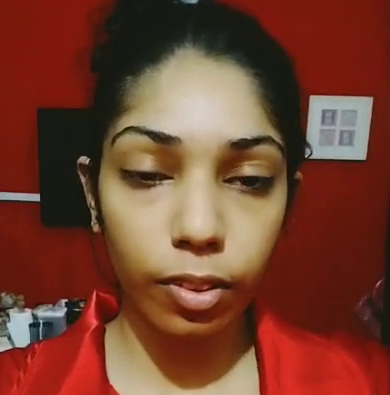

In [32]:
from google.colab import files
up = files.upload()
name = list(up.keys())[0]

out = sample_frames(name)
print(len(out), "crops; times:", [round(t, 1) for t, _ in out][:10])
for t, img in out[:3]:
    display(img)          # look at them with your own eyes

In [34]:
%%writefile predict.py
import os, numpy as np, torch, joblib, open_clip
from PIL import Image

_DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
_HERE = os.path.dirname(os.path.abspath(__file__))

# Loaded once at import time, not per request
_model, _, _preprocess = open_clip.create_model_and_transforms("ViT-B-32", pretrained="openai")
_model = _model.to(_DEVICE).eval()
_clf = joblib.load(os.path.join(_HERE, "deep_clf.joblib"))

# Your teammate's function. Until it exists, we fall back (see predict_image).
try:
    from ml.fractal import predict_fractal      # adjust the path to your repo layout
except ImportError:
    predict_fractal = None

def _load(image):
    if isinstance(image, Image.Image):
        return image.convert("RGB")
    return Image.open(image).convert("RGB")

@torch.no_grad()
def predict_deep(image):
    x = _preprocess(_load(image)).unsqueeze(0).to(_DEVICE)
    v = _model.encode_image(x)
    v = v / v.norm(dim=-1, keepdim=True)
    return float(_clf.predict_proba(v.cpu().numpy())[0, 1])    # P(fake)

def _placeholder_patches(img, score):
    # TEMPORARY: right shape per the contract, but carries no information
    w, h = img.size
    if min(w, h) < 128:
        s = 128 / min(w, h)
        w, h = round(w * s), round(h * s)
    rows, cols = (h - 64) // 32 + 1, (w - 64) // 32 + 1
    return [[score] * cols for _ in range(rows)]

def predict_image(image):
    img = _load(image)
    deep = predict_deep(img)
    if predict_fractal is None:
        return {"score": deep, "patch_scores": _placeholder_patches(img, deep)}
    fr = predict_fractal(img)
    # Fusion goes here once the fractal branch exists (next step)
    return {"score": deep, "patch_scores": fr["patch_scores"]}

Overwriting predict.py


In [35]:
# 1. Verify the file exists in your Google Drive
!ls -la /content/drive/MyDrive/deep_clf.joblib

# 2. Copy the file into your local Colab directory where predict.py expects it
!cp /content/drive/MyDrive/deep_clf.joblib /content/deep_clf.joblib

print("File successfully copied to local workspace!")

-rw------- 1 root root 4959 Oct 18 22:15 /content/drive/MyDrive/deep_clf.joblib
File successfully copied to local workspace!


In [36]:
import random
from predict import predict_deep, predict_image

random.seed(1)
real = random.sample(list_images(f"{base}/valid/real"), 5)
fake = random.sample(list_images(f"{base}/valid/fake"), 5)
print("real:", [round(predict_deep(p), 2) for p in real])    # expect mostly low
print("fake:", [round(predict_deep(p), 2) for p in fake])    # expect mostly high

# Now your own video crops, which is the more interesting test
for t, img in sample_frames(name)[:5]:
    print(round(t, 1), round(predict_deep(img), 2))

real: [0.0, 0.0, 0.0, 0.0, 0.0]
fake: [0.99, 0.91, 1.0, 0.99, 0.84]
1.0 0.0
2.0 0.0
3.0 0.0
4.0 0.0
5.0 0.0


In [37]:
scores = [predict_deep(img) for t, img in out]
print([round(s, 2) for s in scores])
print("mean:", round(float(np.mean(scores)), 2))

[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0]
mean: 0.0


In [38]:
%%writefile video_utils.py
import cv2
from PIL import Image

_face_cascade = cv2.CascadeClassifier(
    cv2.data.haarcascades + "haarcascade_frontalface_default.xml")

def _largest_face(frame_bgr):
    gray = cv2.cvtColor(frame_bgr, cv2.COLOR_BGR2GRAY)
    faces = _face_cascade.detectMultiScale(
        gray, scaleFactor=1.1, minNeighbors=5, minSize=(60, 60))
    if len(faces) == 0:
        return None
    return max(faces, key=lambda f: f[2] * f[3])

def sample_frames(path, every_sec=1.0, max_frames=30, margin=0.3):
    cap = cv2.VideoCapture(path)
    if not cap.isOpened():
        raise ValueError("unreadable video")
    fps = cap.get(cv2.CAP_PROP_FPS) or 25.0
    step = max(1, int(round(fps * every_sec)))
    results, idx = [], 0
    while len(results) < max_frames:
        ok, frame = cap.read()
        if not ok:
            break
        if idx % step == 0:
            box = _largest_face(frame)
            if box is not None:
                x, y, w, h = box
                m = int(margin * max(w, h))
                H, W = frame.shape[:2]
                crop = frame[max(0, y - m):min(H, y + h + m),
                             max(0, x - m):min(W, x + w + m)]
                img = Image.fromarray(cv2.cvtColor(crop, cv2.COLOR_BGR2RGB))
                results.append((idx / fps, img))
        idx += 1
    cap.release()
    return results

Writing video_utils.py


In [39]:
import sklearn, torch, open_clip, cv2, joblib
print("scikit-learn==" + sklearn.__version__)
print("torch==" + torch.__version__)
print("open_clip_torch==" + open_clip.__version__)
print("opencv-python-headless==" + cv2.__version__)
print("joblib==" + joblib.__version__)

scikit-learn==1.6.1
torch==2.11.0+cu130
open_clip_torch==3.3.0
opencv-python-headless==4.14.0
joblib==1.6.0


In [40]:
from google.colab import files
for f in ["predict.py", "video_utils.py", "deep_clf.joblib"]:
    files.download(f)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>